# 02 - Clasificación
Proyecto Final de Minería de Datos
Análisis de la intención de compra en comercio electrónico (Online Shoppers Purchasing Intention Dataset, UCI)

Responsable: Alain Cesar Raymundo

## Objetivo
Predecir si una sesión de navegación termina en compra (`Revenue`: 1 = compra, 0 = no compra) y comparar el desempeño de tres modelos de clasificación: **regresión logística**, **árbol de decisión** y **Random Forest**.

## Punto de partida (notebook 01)
- Se usa `data/datos_codificados.csv`: datos ya limpios (sin duplicados) y con one-hot encoding en las variables nominales.
- La columna `conjunto` trae la partición 80 % `train` / 20 % `test`, estratificada por `Revenue` con `random_state=42`. Es la misma para todo el equipo.
- Las clases están desbalanceadas (alrededor de 16 % de las sesiones terminan en compra), así que además de accuracy se reportan precision, recall, F1 y la matriz de confusión.

## Organización del notebook
1. Configuración y carga de datos
2. Selección de características (solo con `train`)
3. Entrenamiento y validación
4. Evaluación en `test`
5. Interpretación de los modelos
6. Conclusiones

## 0. Configuración

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, classification_report, RocCurveDisplay)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")

# Parámetros del proyecto (los mismos del notebook 01; no cambiar sin avisar al equipo)
RANDOM_STATE = 42
RUTA_CSV = "data/datos_codificados.csv"

## 1. Carga de datos y partición

In [3]:
df = pd.read_csv(RUTA_CSV)

# "conjunto" trae la partición definida en el notebook 01
train = df[df["conjunto"] == "train"]
test = df[df["conjunto"] == "test"]

# X = características, y = variable objetivo.
# "conjunto" no es una característica, así que se quita junto con Revenue.
COLS_EXCLUIR = ["Revenue", "conjunto"]
X_train, y_train = train.drop(columns=COLS_EXCLUIR), train["Revenue"]
X_test,  y_test  = test.drop(columns=COLS_EXCLUIR),  test["Revenue"]

print("Filas y columnas del CSV:", df.shape)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Nulos en X_train:", X_train.isna().sum().sum(), "| Nulos en X_test:", X_test.isna().sum().sum())

Filas y columnas del CSV: (12205, 77)
Entrenamiento: (9764, 75) | Prueba: (2441, 75)
Nulos en X_train: 0 | Nulos en X_test: 0


In [4]:
# Balance de clases en cada partición
etiquetas = {0: "No compra", 1: "Compra"}
balance = pd.DataFrame({
    "train": y_train.value_counts().rename(etiquetas),
    "test": y_test.value_counts().rename(etiquetas),
})
balance["% train"] = balance["train"] / balance["train"].sum() * 100
balance["% test"] = balance["test"] / balance["test"].sum() * 100
display(balance)

# Línea base: un "modelo" que siempre responde "no compra"
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
acc_base = accuracy_score(y_test, base.predict(X_test))
print(f"Accuracy de responder siempre 'no compra': {acc_base:.4f}")

,train,test,% train,% test
Revenue,,,,
No compra,8238,2059,84.3712,84.3507
Compra,1526,382,15.6288,15.6493


Accuracy de responder siempre 'no compra': 0.8435


Observaciones:


- La partición conserva la proporción de clases: alrededor de 15.6 % de compras tanto en `train` (1,526 de 9,764 sesiones) como en `test` (382 de 2,441).
- Un modelo que siempre responda "no compra" alcanza una accuracy de 0.8435 sin detectar ninguna compra (precision y recall de la clase "compra" = 0). Por eso accuracy no sirve sola para evaluar: los modelos tienen que superar esa línea base **y** detectar compras, y se juzgan principalmente con F1 y recall de la clase "compra".

## 2. Selección de características (solo con `train`)

Se aplican tres filtros, en este orden. Todo se calcula únicamente con `train` para que la partición de `test` no influya en las decisiones.

1. **Varianza casi nula:** variables que casi no cambian (por ejemplo, dummies de categorías muy raras) no ayudan a predecir y solo agregan ruido.
2. **Correlación alta (|r| > 0.80):** si dos variables dicen casi lo mismo, se conserva la que tiene más información sobre `Revenue`. Quitar redundancia hace más estables los coeficientes de la regresión logística y más fácil de interpretar el resultado.
3. **Información mutua con `Revenue`:** se descartan las variables que no aportan información sobre la compra.

In [5]:
# 2.1 Información mutua de cada variable con Revenue (misma función y semilla que el notebook 01)
mi = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
mi = pd.Series(mi, index=X_train.columns).sort_values(ascending=False)

# 2.2 Filtro de varianza: quitar variables casi constantes
UMBRAL_VARIANZA = 0.001
varianza = X_train.var()
quitar_varianza = list(varianza[varianza < UMBRAL_VARIANZA].index)
print(f"Quitadas por varianza < {UMBRAL_VARIANZA} ({len(quitar_varianza)}):")
print(quitar_varianza)

# Candidatas, ya ordenadas de mayor a menor información mutua
candidatas = [c for c in mi.index if c not in quitar_varianza]

Quitadas por varianza < 0.001 (9):
['OperatingSystems_5', 'OperatingSystems_7', 'Browser_9', 'Browser_11', 'Browser_12', 'TrafficType_12', 'TrafficType_16', 'TrafficType_17', 'TrafficType_18']


In [6]:
# 2.3 Filtro de correlación
# Se recorren las variables de mayor a menor información mutua y cada una se conserva solo si no está
# muy correlacionada (|r| > 0.80) con otra que ya se conservó. Así, de cada grupo de variables parecidas
# se queda la que más informa sobre Revenue.
UMBRAL_CORR = 0.80
corr = X_train[candidatas].corr().abs()

conservadas, quitar_corr = [], {}
for col in candidatas:
    parecidas = [c for c in conservadas if corr.loc[col, c] > UMBRAL_CORR]
    if parecidas:
        quitar_corr[col] = parecidas[0]   # (variable quitada -> variable que se conserva en su lugar)
    else:
        conservadas.append(col)

print(f"Quitadas por correlación ({len(quitar_corr)}):")
for col, parecida in quitar_corr.items():
    print(f"  {col:28s} se parece a {parecida:28s} (|r| = {corr.loc[col, parecida]:.3f})")

Quitadas por correlación (6):
  TotalDuration                se parece a ProductRelated_Duration      (|r| = 0.994)
  TotalPages                   se parece a ProductRelated_Duration      (|r| = 0.853)
  BounceRates                  se parece a ExitRates                    (|r| = 0.900)
  ProductRelated               se parece a ProductRelated_Duration      (|r| = 0.853)
  NonProductDuration           se parece a Administrative_Duration      (|r| = 0.839)
  SpecialDay                   se parece a IsSpecialDay                 (|r| = 0.919)


In [7]:
# 2.4 Filtro de información mutua: se descartan las variables que casi no informan sobre Revenue
UMBRAL_MI = 0.001
CARACTERISTICAS = [c for c in conservadas if mi[c] > UMBRAL_MI]
descartadas_mi = [c for c in conservadas if mi[c] <= UMBRAL_MI]

print(f"Descartadas por información mutua <= {UMBRAL_MI} ({len(descartadas_mi)}):")
print(descartadas_mi)
print(f"\nResumen: {X_train.shape[1]} variables iniciales -> {len(CARACTERISTICAS)} seleccionadas")
print(CARACTERISTICAS)

Descartadas por información mutua <= 0.001 (35):
['TrafficType_7', 'Month_Aug', 'OperatingSystems_2', 'TrafficType_2', 'Weekend', 'TrafficType_3', 'Browser_8', 'Browser_6', 'Browser_7', 'Browser_5', 'Browser_3', 'Browser_4', 'Browser_2', 'VisitorType_Other', 'OperatingSystems_4', 'OperatingSystems_3', 'Month_Jun', 'Month_Mar', 'Month_May', 'Month_Jul', 'Month_Sep', 'Month_Oct', 'Region_3', 'Region_9', 'Region_8', 'Region_7', 'Browser_10', 'Browser_13', 'TrafficType_8', 'TrafficType_9', 'TrafficType_6', 'TrafficType_14', 'TrafficType_15', 'TrafficType_19', 'TrafficType_20']

Resumen: 75 variables iniciales -> 25 seleccionadas
['PageValues', 'HasPageValue', 'ExitRates', 'ProductRelated_Duration', 'Administrative', 'ProductPageRatio', 'AvgTimePerPage', 'Administrative_Duration', 'Month_Nov', 'VisitorType_Returning_Visitor', 'Informational_Duration', 'TrafficType_11', 'Region_2', 'TrafficType_4', 'Region_6', 'TrafficType_10', 'Month_Dec', 'IsSpecialDay', 'OperatingSystems_8', 'Region_4', '

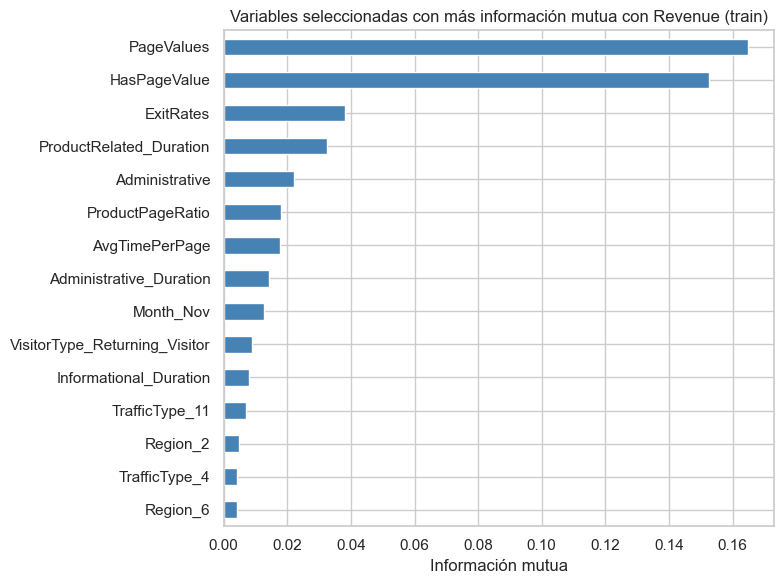

In [8]:
# Top 15 de las variables seleccionadas por información mutua
mi[CARACTERISTICAS].head(15).sort_values().plot(kind="barh", figsize=(8, 6), color="steelblue")
plt.title("Variables seleccionadas con más información mutua con Revenue (train)")
plt.xlabel("Información mutua")
plt.tight_layout()
plt.show()

Observaciones:


- **Varianza:** se quitaron 9 variables, todas dummies de categorías muy raras (por ejemplo `Browser_9`, `OperatingSystems_5` o `TrafficType_12`), que casi nunca valen 1.
- **Correlación:** se quitaron 6 variables redundantes. `TotalDuration`, `TotalPages` y `ProductRelated` quedaron representadas por `ProductRelated_Duration`; `BounceRates` por `ExitRates` (|r| = 0.90); `NonProductDuration` por `Administrative_Duration`; y `SpecialDay` por `IsSpecialDay`.
- **Información mutua:** se descartaron 35 variables con información casi nula sobre `Revenue`, sobre todo dummies de `Browser`, `TrafficType`, `Region` y `OperatingSystems`, además de `Weekend` y la mayoría de los meses (se conservan `Month_Nov` y `Month_Dec`).
- Resultado: de 75 variables se pasa a 25. `PageValues` y `HasPageValue` tienen mucha más información mutua con `Revenue` que cualquier otra; después siguen `ExitRates` y `ProductRelated_Duration`.

### 2.5 ¿Sirvió la selección?
Se compara el F1 (validación cruzada de 5 folds sobre `train`) de dos modelos sencillos usando todas las variables contra usar solo las seleccionadas. Si el F1 es parecido, la selección simplificó el modelo sin perder capacidad de predicción.

In [9]:
# Validación cruzada estratificada: mantiene la proporción de compras en cada fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pruebas = {
    "Regresión logística": Pipeline([
        ("escalador", StandardScaler()),
        ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                            random_state=RANDOM_STATE, n_jobs=-1),
}

filas = []
for nombre, modelo in pruebas.items():
    f1_todas = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="f1").mean()
    f1_sel = cross_val_score(modelo, X_train[CARACTERISTICAS], y_train, cv=cv, scoring="f1").mean()
    filas.append({"modelo": nombre,
                  f"F1 con todas ({X_train.shape[1]} variables)": f1_todas,
                  f"F1 con seleccionadas ({len(CARACTERISTICAS)} variables)": f1_sel})

pd.DataFrame(filas).set_index("modelo")

,F1 con todas (75 variables),F1 con seleccionadas (25 variables)
modelo,,
Regresión logística,0.6472,0.6513
Random Forest,0.6421,0.6346


Observaciones:


Usar 25 variables en lugar de 75 casi no cambia el F1: sube un poco en la regresión logística (de 0.647 a 0.651) y baja un poco en Random Forest (de 0.642 a 0.635). La diferencia es pequeña, así que la selección simplifica los modelos sin perder capacidad de predicción. Para el resto del notebook se usan las 25 variables seleccionadas.

## 3. Entrenamiento y validación

**Modelos y justificación**
- **Regresión logística:** modelo lineal, rápido e interpretable; sus coeficientes indican en qué dirección empuja cada variable la probabilidad de compra. Necesita variables escaladas, por eso va dentro de un `Pipeline` con `StandardScaler`: el escalador se ajusta solo con los datos de entrenamiento de cada fold, sin ver los de validación.
- **Árbol de decisión:** captura relaciones no lineales y genera reglas fáciles de explicar. No necesita escalar. Es propenso al sobreajuste, por eso se limita su profundidad.
- **Random Forest:** conjunto de muchos árboles; suele generalizar mejor que un árbol solo y entrega la importancia de cada variable.

**Desbalance:** las tres usan `class_weight="balanced"` (o `balanced_subsample` en el bosque) para que equivocarse en una compra (clase minoritaria) cueste más que equivocarse en una no compra.

**Validación:** `GridSearchCV` prueba combinaciones de hiperparámetros con validación cruzada estratificada de 5 folds **dentro de `train`** y elige la que maximiza el **F1 de la clase "compra"**. Elegimos F1 porque con clases desbalanceadas accuracy engaña. El conjunto `test` no se toca hasta la sección 4.

In [10]:
# (modelo base, rejilla de hiperparámetros a probar)
modelos = {
    "Regresión logística": (
        Pipeline([
            ("escalador", StandardScaler()),
            ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
        ]),
        {"modelo__C": [0.01, 0.1, 1, 10]},   # C pequeño = más regularización
    ),
    "Árbol de decisión": (
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"max_depth": [3, 5, 7, 10], "min_samples_leaf": [5, 20, 50]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", random_state=RANDOM_STATE),
        {"max_depth": [8, 12, None], "min_samples_leaf": [1, 5, 10]},
    ),
}

X_train_sel = X_train[CARACTERISTICAS]
X_test_sel = X_test[CARACTERISTICAS]

mejores, resumen_cv = {}, []
for nombre, (modelo, rejilla) in modelos.items():
    busqueda = GridSearchCV(modelo, rejilla, cv=cv, scoring="f1", n_jobs=-1)
    busqueda.fit(X_train_sel, y_train)
    mejores[nombre] = busqueda.best_estimator_
    resumen_cv.append({"modelo": nombre, "mejores hiperparámetros": busqueda.best_params_,
                       "F1 validación cruzada": busqueda.best_score_})

pd.DataFrame(resumen_cv).set_index("modelo")

,mejores hiperparámetros,F1 validación cruzada
modelo,,
Regresión logística,{'modelo__C': 0.01},0.6574
Árbol de decisión,"{'max_depth': 5, 'min_samples_leaf': 50}",0.6489
Random Forest,"{'max_depth': None, 'min_samples_leaf': 5}",0.6766


Observaciones:


- **Regresión logística:** mejor `C = 0.01` (regularización fuerte), F1 de validación de 0.657. El mejor valor quedó en el extremo de la rejilla, así que se podrían probar valores aún menores.
- **Árbol de decisión:** mejor con `max_depth = 5` y `min_samples_leaf = 50` (F1 de validación 0.649). Un árbol poco profundo y con hojas grandes generaliza mejor que uno profundo.
- **Random Forest:** mejor con `max_depth = None` y `min_samples_leaf = 5` (F1 de validación 0.677), el más alto de los tres.

## 4. Evaluación en `test`

Con los mejores hiperparámetros ya elegidos, se evalúa una sola vez en `test` (datos que ningún modelo vio). Métricas, tomando "compra" como clase positiva:
- **Accuracy:** proporción de sesiones bien clasificadas.
- **Precision:** de las sesiones que el modelo dijo "compra", cuántas sí compraron.
- **Recall:** de las sesiones que sí compraron, cuántas detectó el modelo.
- **F1:** media armónica de precision y recall.
- **ROC-AUC:** qué tan bien separa compras de no compras en general, sin depender del umbral de 0.5.

In [11]:
def calcular_metricas(modelo, X, y):
    pred = modelo.predict(X)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, modelo.predict_proba(X)[:, 1]),
    }

resultados = {"Línea base (siempre no compra)": calcular_metricas(base, X_test, y_test)}
for nombre, modelo in mejores.items():
    resultados[nombre] = calcular_metricas(modelo, X_test_sel, y_test)

tabla_metricas = pd.DataFrame(resultados).T
tabla_metricas

,Accuracy,Precision,Recall,F1,ROC-AUC
Línea base (siempre no compra),0.8435,0.0000,0.0000,0.0000,0.5000
Regresión logística,0.8619,0.5387,0.8194,0.6501,0.9263
Árbol de decisión,0.8640,0.5425,0.8351,0.6577,0.9219
Random Forest,0.8779,0.5830,0.7723,0.6644,0.9281


In [12]:
# Reporte por clase de cada modelo
for nombre, modelo in mejores.items():
    print(f"=== {nombre} ===")
    print(classification_report(y_test, modelo.predict(X_test_sel),
                                target_names=["No compra", "Compra"], digits=3))

=== Regresión logística ===
              precision    recall  f1-score   support

   No compra      0.963     0.870     0.914      2059
      Compra      0.539     0.819     0.650       382

    accuracy                          0.862      2441
   macro avg      0.751     0.845     0.782      2441
weighted avg      0.897     0.862     0.873      2441

=== Árbol de decisión ===
              precision    recall  f1-score   support

   No compra      0.966     0.869     0.915      2059
      Compra      0.543     0.835     0.658       382

    accuracy                          0.864      2441
   macro avg      0.754     0.852     0.786      2441
weighted avg      0.900     0.864     0.875      2441

=== Random Forest ===
              precision    recall  f1-score   support

   No compra      0.955     0.898     0.925      2059
      Compra      0.583     0.772     0.664       382

    accuracy                          0.878      2441
   macro avg      0.769     0.835     0.795      244

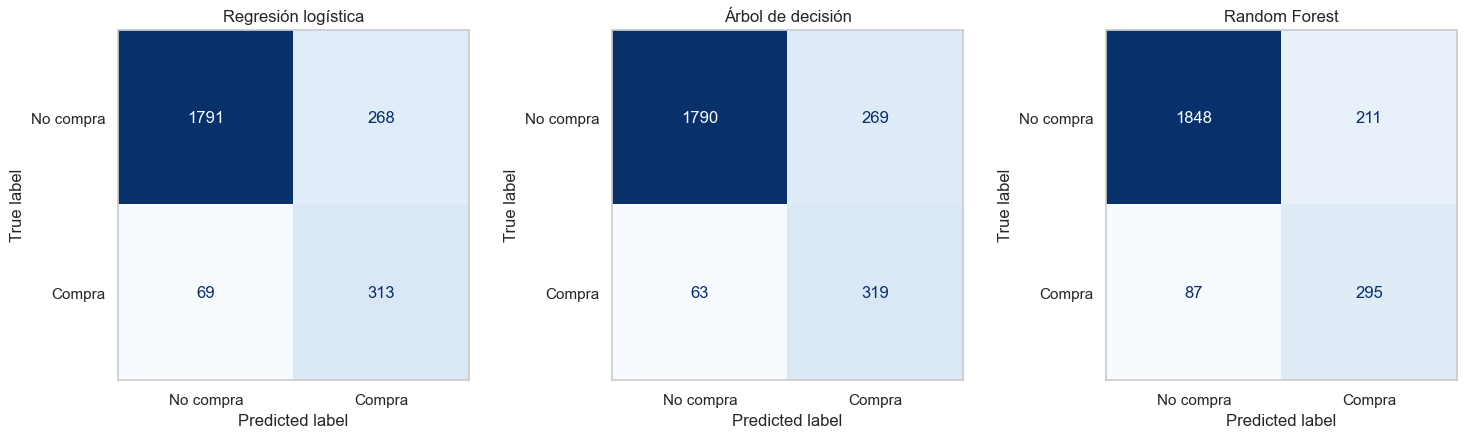

In [13]:
# Matrices de confusión (filas = real, columnas = predicho)
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (nombre, modelo) in zip(ejes, mejores.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, modelo.predict(X_test_sel), display_labels=["No compra", "Compra"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nombre)
    ax.grid(False)
plt.tight_layout()
plt.show()

Observaciones de las matrices de confusión:


En `test` hay 2,059 sesiones sin compra y 382 con compra.
- **Regresión logística:** detecta 313 de las 382 compras (69 se le escapan) y marca por error 268 sesiones como compra.
- **Árbol de decisión:** detecta 319 compras (63 falsos negativos) con 269 falsos positivos. Es el que menos compras pierde.
- **Random Forest:** detecta 295 compras (87 falsos negativos) pero solo 211 falsos positivos, el menor número de falsas alarmas.

La diferencia entre modelos es un intercambio entre dos errores: el bosque se equivoca menos al avisar "compra", pero deja pasar más compradores reales.

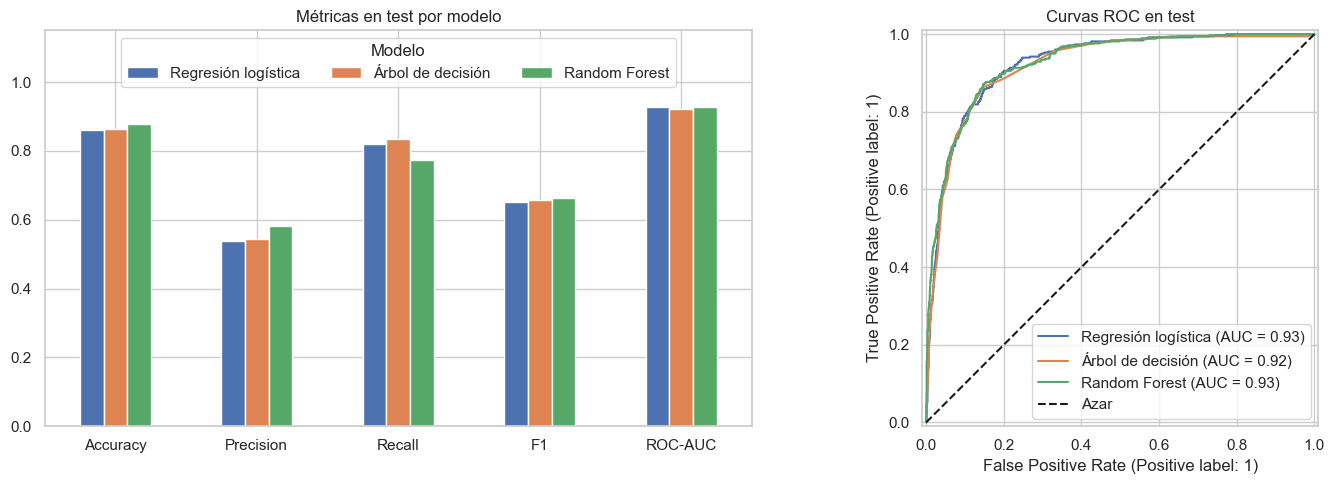

In [14]:
# Comparación gráfica de métricas y curvas ROC
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))

tabla_metricas.drop(index="Línea base (siempre no compra)")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]] \
    .T.plot(kind="bar", ax=ejes[0], rot=0)
ejes[0].set_title("Métricas en test por modelo")
ejes[0].set_ylim(0, 1.15)
ejes[0].legend(title="Modelo", loc="upper center", ncol=3)

for nombre, modelo in mejores.items():
    RocCurveDisplay.from_estimator(modelo, X_test_sel, y_test, name=nombre, ax=ejes[1])
ejes[1].plot([0, 1], [0, 1], "k--", label="Azar")
ejes[1].set_title("Curvas ROC en test")
ejes[1].legend()

plt.tight_layout()
plt.show()

Observaciones de las métricas:


- Los tres modelos superan con claridad la línea base: detectan entre 77 % y 84 % de las compras y tienen ROC-AUC de 0.92 a 0.93.
- **Random Forest** tiene la mejor accuracy (0.878), precision (0.583), F1 (0.664) y ROC-AUC (0.928).
- **Árbol de decisión** y **regresión logística** tienen mayor recall (0.835 y 0.819, contra 0.772 del bosque), pero menor precision (0.54).
- Las diferencias entre modelos son pequeñas (F1 entre 0.650 y 0.664). Con solo 382 compras en `test`, una diferencia de un punto de F1 está dentro del margen de variación, así que no se puede afirmar que un modelo sea claramente mejor que los otros. La elección depende del objetivo: si importa detectar la mayor cantidad de compradores, conviene el árbol o la regresión logística; si importa que los avisos de "compra" sean más confiables, el bosque.
- En todos los casos la precision queda alrededor de 0.54 a 0.58: de cada 10 sesiones que el modelo marca como compra, 4 no compran. Es el costo de priorizar el recall en una clase minoritaria.

### 4.1 ¿Hay sobreajuste?
Se compara el F1 del modelo en `train` contra el F1 de validación cruzada y el de `test`. Si en `train` es mucho más alto que en los otros dos, el modelo memorizó los datos de entrenamiento.

In [15]:
cv_f1 = {fila["modelo"]: fila["F1 validación cruzada"] for fila in resumen_cv}

comparacion = pd.DataFrame({
    nombre: {
        "F1 train": f1_score(y_train, modelo.predict(X_train_sel)),
        "F1 validación cruzada": cv_f1[nombre],
        "F1 test": f1_score(y_test, modelo.predict(X_test_sel)),
    }
    for nombre, modelo in mejores.items()
}).T
comparacion["train - test"] = comparacion["F1 train"] - comparacion["F1 test"]
comparacion

,F1 train,F1 validación cruzada,F1 test,train - test
Regresión logística,0.6590,0.6574,0.6501,0.0089
Árbol de decisión,0.6663,0.6489,0.6577,0.0086
Random Forest,0.7777,0.6766,0.6644,0.1133


Observaciones:


- **Regresión logística y árbol de decisión:** el F1 en `train`, en validación cruzada y en `test` es muy parecido (diferencia de 0.009). No hay sobreajuste importante.
- **Random Forest:** el F1 en `train` (0.778) es mucho mayor que en validación (0.677) y en `test` (0.664). El bosque con árboles profundos memoriza parte de los datos de entrenamiento. Aun así su F1 en `test` es el más alto y es consistente con el de validación cruzada, por lo que la estimación de su desempeño sigue siendo confiable; para reducir el sobreajuste se podrían probar árboles menos profundos u hojas más grandes.

## 5. Interpretación de los modelos

¿Qué variables pesan más para predecir la compra? Se revisa cada modelo con su propia herramienta:
- **Random Forest:** importancia de cada variable (cuánto reduce la impureza en promedio).
- **Regresión logística:** coeficientes sobre variables estandarizadas, así que son comparables entre sí. Positivo = aumenta la probabilidad de compra; negativo = la disminuye.
- **Árbol de decisión:** las primeras divisiones del árbol muestran las reglas más importantes.

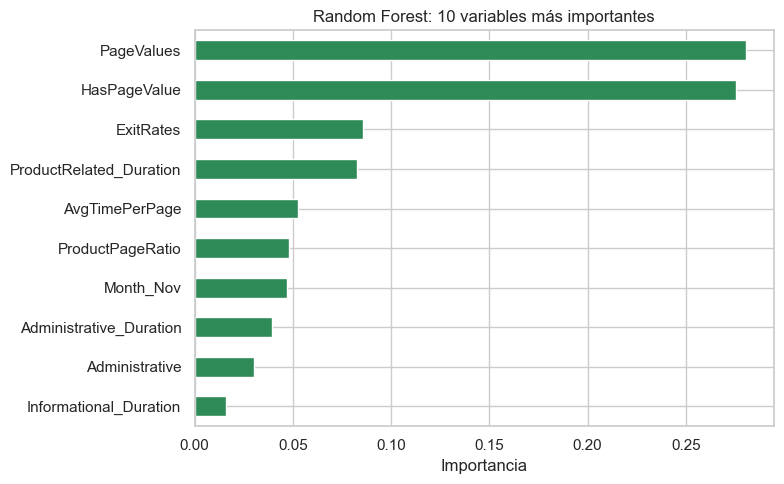

,importancia
PageValues,0.2809
HasPageValue,0.2757
ExitRates,0.0859
ProductRelated_Duration,0.0829
AvgTimePerPage,0.0526
ProductPageRatio,0.0479
Month_Nov,0.0470
Administrative_Duration,0.0392
Administrative,0.0300
Informational_Duration,0.0161


In [16]:
# Importancia de variables en Random Forest
bosque = mejores["Random Forest"]
importancias = pd.Series(bosque.feature_importances_, index=CARACTERISTICAS).sort_values(ascending=False)

importancias.head(10).sort_values().plot(kind="barh", figsize=(8, 5), color="seagreen")
plt.title("Random Forest: 10 variables más importantes")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()

importancias.head(10).to_frame("importancia")

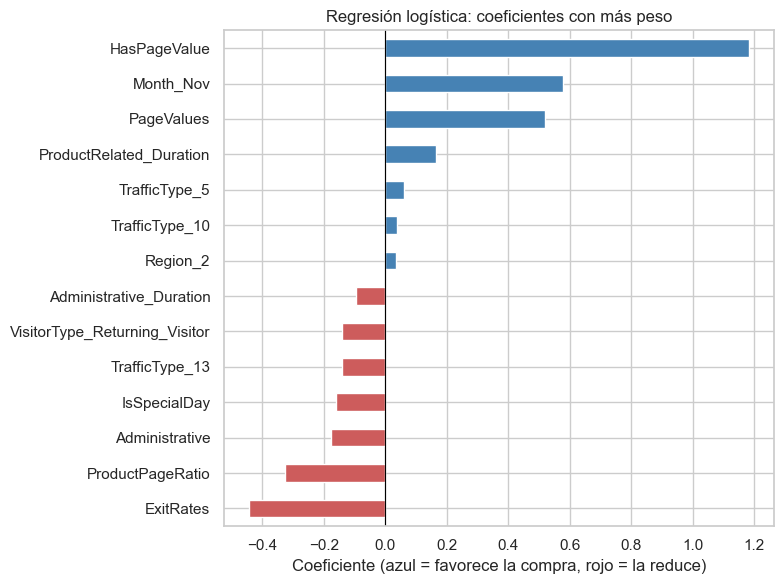

,coeficiente
HasPageValue,1.1837
Month_Nov,0.5796
PageValues,0.5212
ProductRelated_Duration,0.1658
TrafficType_5,0.0618
TrafficType_10,0.0386
Region_2,0.0342
Administrative_Duration,-0.0967
VisitorType_Returning_Visitor,-0.1392
TrafficType_13,-0.1394


In [17]:
# Coeficientes de la regresión logística (variables estandarizadas)
coef = pd.Series(mejores["Regresión logística"].named_steps["modelo"].coef_[0], index=CARACTERISTICAS)
coef_top = pd.concat([coef.sort_values().head(7), coef.sort_values().tail(7)])

colores = ["indianred" if v < 0 else "steelblue" for v in coef_top]
coef_top.plot(kind="barh", figsize=(8, 6), color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Regresión logística: coeficientes con más peso")
plt.xlabel("Coeficiente (azul = favorece la compra, rojo = la reduce)")
plt.tight_layout()
plt.show()

coef_top.sort_values(ascending=False).to_frame("coeficiente")

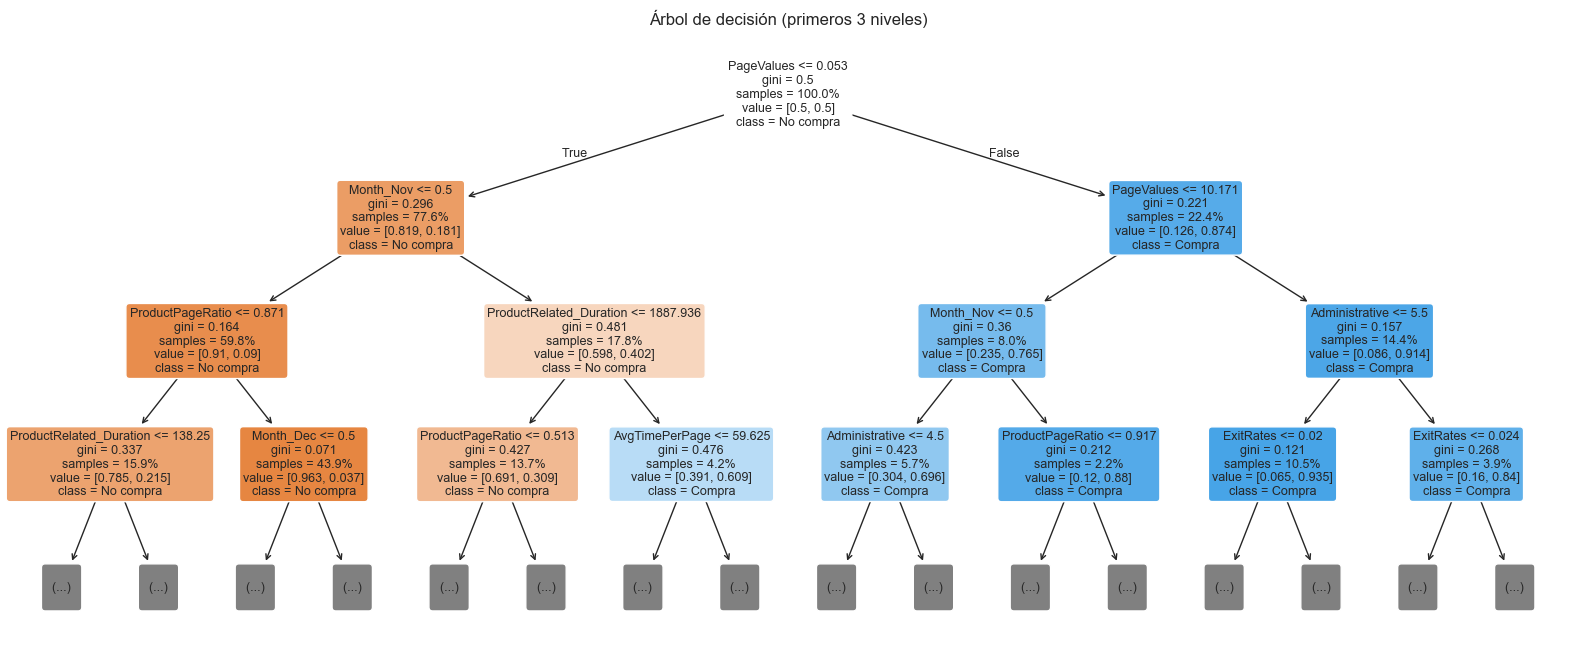

In [18]:
# Primeras divisiones del árbol de decisión (se muestran solo 3 niveles para que sea legible)
arbol = mejores["Árbol de decisión"]
plt.figure(figsize=(20, 8))
plot_tree(arbol, max_depth=3, feature_names=CARACTERISTICAS, class_names=["No compra", "Compra"],
          filled=True, rounded=True, fontsize=9, proportion=True)
plt.title("Árbol de decisión (primeros 3 niveles)")
plt.show()

Observaciones:


- **Random Forest:** `PageValues` (0.28) y `HasPageValue` (0.28) concentran más de la mitad de la importancia. Les siguen `ExitRates` (0.09), `ProductRelated_Duration` (0.08), `AvgTimePerPage`, `ProductPageRatio`, `Month_Nov` y `Administrative_Duration`.
- **Regresión logística:** los coeficientes más positivos son `HasPageValue` (aprox. +1.2), `Month_Nov` (aprox. +0.6), `PageValues` (aprox. +0.5) y `ProductRelated_Duration`. Reducen la probabilidad de compra `ExitRates` (aprox. -0.4), `ProductPageRatio`, `Administrative`, `IsSpecialDay` y `VisitorType_Returning_Visitor`.
- **Árbol de decisión:** la primera división es `PageValues <= 0.053`. Las sesiones con `PageValues` mayor a cero se clasifican como compra en su gran mayoría; en las demás el árbol revisa si es noviembre (`Month_Nov`), la proporción de páginas de producto (`ProductPageRatio`) y el tiempo en páginas de producto. Nota: el campo `value` de cada nodo muestra proporciones ponderadas por `class_weight="balanced"`, por eso el nodo raíz aparece como [0.5, 0.5].
- Los tres modelos coinciden: lo que más predice la compra es que la sesión haya pasado por páginas con valor (`PageValues`), seguida de una baja tasa de salida, más tiempo en páginas de producto y la temporada de noviembre.

## 6. Conclusiones de clasificación


**Resultados**
- Los tres modelos permiten predecir la compra mucho mejor que la línea base (accuracy de 0.8435 sin detectar ninguna compra): F1 de 0.65 a 0.66, recall de 0.77 a 0.84 y ROC-AUC de 0.92 a 0.93 en `test`.
- **Random Forest** obtuvo el mejor F1 (0.664), accuracy (0.878) y ROC-AUC (0.928), pero la ventaja sobre la regresión logística y el árbol es pequeña y está dentro del margen de variación. La **regresión logística** es la opción más simple, no se sobreajusta y es fácil de explicar. El **árbol de decisión** detecta más compras (recall de 0.835) con reglas legibles.
- Cuál usar depende del costo de cada error: si perder un comprador es más grave que hacer una oferta a quien no iba a comprar, conviene el árbol o la regresión logística; si cada aviso tiene un costo, conviene el bosque.

**Variables relevantes**
- `PageValues` y `HasPageValue` dominan en los tres modelos. Después aparecen `ExitRates` (más salidas, menos compras), el tiempo en páginas de producto y noviembre como mes con más compras.
- Seleccionar variables redujo el modelo de 75 a 25 columnas sin pérdida notable de F1.

**Limitaciones**
- `PageValues` se calcula con el valor de las páginas visitadas antes de completar una transacción, por lo que está muy cerca de lo que se quiere predecir. Si en un caso real esa variable no estuviera disponible antes de la compra, el desempeño sería menor al reportado aquí.
- Hay desbalance (15.6 % de compras) y el umbral de decisión se dejó en 0.5; la precision de 0.54 a 0.58 indica que cerca de 4 de cada 10 avisos de compra son falsas alarmas.
- Las variables `OperatingSystems`, `Browser`, `Region` y `TrafficType` son códigos anónimos, así que no se pueden interpretar. El dataset cubre 10 meses (no hay enero ni abril) y un solo sitio, por lo que el efecto de noviembre puede deberse a la temporada de ese año.
- Se usó una sola partición `train`/`test` y rejillas de hiperparámetros pequeñas.

